In [1]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from matplotlib.colors import LogNorm, Normalize
import proplot as plot
import rioxarray
import xarray as xr
import numpy as np
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import warnings
import geopandas as gpd
plot.rc['cmap.discrete'] = False
import os
warnings.filterwarnings("ignore")

ERROR 1: PROJ: proj_create_from_database: Open of /home/alessandrom/anaconda3/envs/bias_correction_conda/share/proj failed
/home/alessandrom/anaconda3/envs/bias_correction_conda/lib/python3.10/site-packages/gribapi/__init__.py:23: UserWarning: ecCodes 2.31.0 or higher is recommended. You are running version 2.16.0
  warnings.warn(


In [2]:
country = 'cuba'

In [3]:
geom_path = '../world_map/ne_50m_admin_0_countries.shp'
geometries = gpd.read_file(geom_path)
geometries = geometries[geometries['NAME_EN'] == f'{country.capitalize()}']['geometry']

In [4]:
month = 1
in_path   = f'../data/atlas_data/{country}/10m_wind_integrated_{country}_m{month}.nc'
months_names = ['January','February','March','April','May','June','July',
                'August','September','October','November','December']
xdf = xr.open_mfdataset(in_path)

In [5]:
#Annual Plot: Opening the monthly files and concatenate, averaging.

#files_list = []
#for month in range(1,13):
    #in_path   = f'../data/atlas_data/{country}/10m_wind_integrated_{country}_m{month}.nc'
#    month_file = xr.open_mfdataset(in_path).assign(month=month)
#    files_list.append(month_file)
#xdf = xr.concat(files_list,dim='month').mean('month')

In [6]:
output_path = f'../data/figures/{country}/'
output_dir = os.path.dirname(output_path)
os.makedirs(output_dir, exist_ok=True)

### Wind Direction

In [7]:
def draw_dir(xdf, vmin, vmax, legend=False, label=None, title=None, suptitle=None, orient='vertical'):
    fig, ax = plot.subplots(figsize=(12, 6), subplot_kw={'projection': ccrs.PlateCarree()})

    # Add features to the map

    ax.add_feature(cfeature.LAKES, edgecolor='black', facecolor='light blue')
    ax.add_feature(cfeature.OCEAN, edgecolor='light blue')
    ax.add_feature(cfeature.RIVERS, edgecolor='light blue')
    ax.add_feature(cfeature.COASTLINE, edgecolor='black', linewidth=1.2)
    ax.add_feature(cfeature.BORDERS, edgecolor='black', linewidth=1.2)

    xdf.rio.set_spatial_dims(x_dim="longitude", y_dim="latitude", inplace=True)
    xdf.rio.write_crs("epsg:4326", inplace=True)
    
    cbar_kwargs = {
        'orientation': 'vertical',
        'shrink': 0.25,
        'aspect': 50,
        'pad': 2,
        'label': label,
        'labelsize': 11,
        
    } if legend else None
    im = xr.plot.pcolormesh(xdf, cmap='Phase', # cyclic colorbar is useful for wind direction
                            ax = ax, 
                            #norm=LogNorm(),
                            vmin=vmin, vmax=vmax,
                            add_colorbar=legend, 
                            add_labels=False, 
                            cbar_kwargs=cbar_kwargs, 
                       )

    if orient == 'horizontal':
        cbar = im.colorbar
        cbar.ax.tick_params(axis='y', rotation=90)
        
    # Add longitude-latitude grid
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
    gl.xlabels_top = False
    gl.ylabels_right = False
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER

    lat_min = np.min(xdf.latitude.values)
    lat_max = np.max(xdf.latitude.values)
    lon_min = np.min(xdf.longitude.values)
    lon_max = np.max(xdf.longitude.values)

    ax.set_extent([lon_min-0.5, lon_max+0.5, lat_min-0.5, lat_max+0.5], crs=ccrs.PlateCarree())
    ax.set_title(title, fontsize=14)
    fig.suptitle(suptitle,fontsize=17)
    return fig

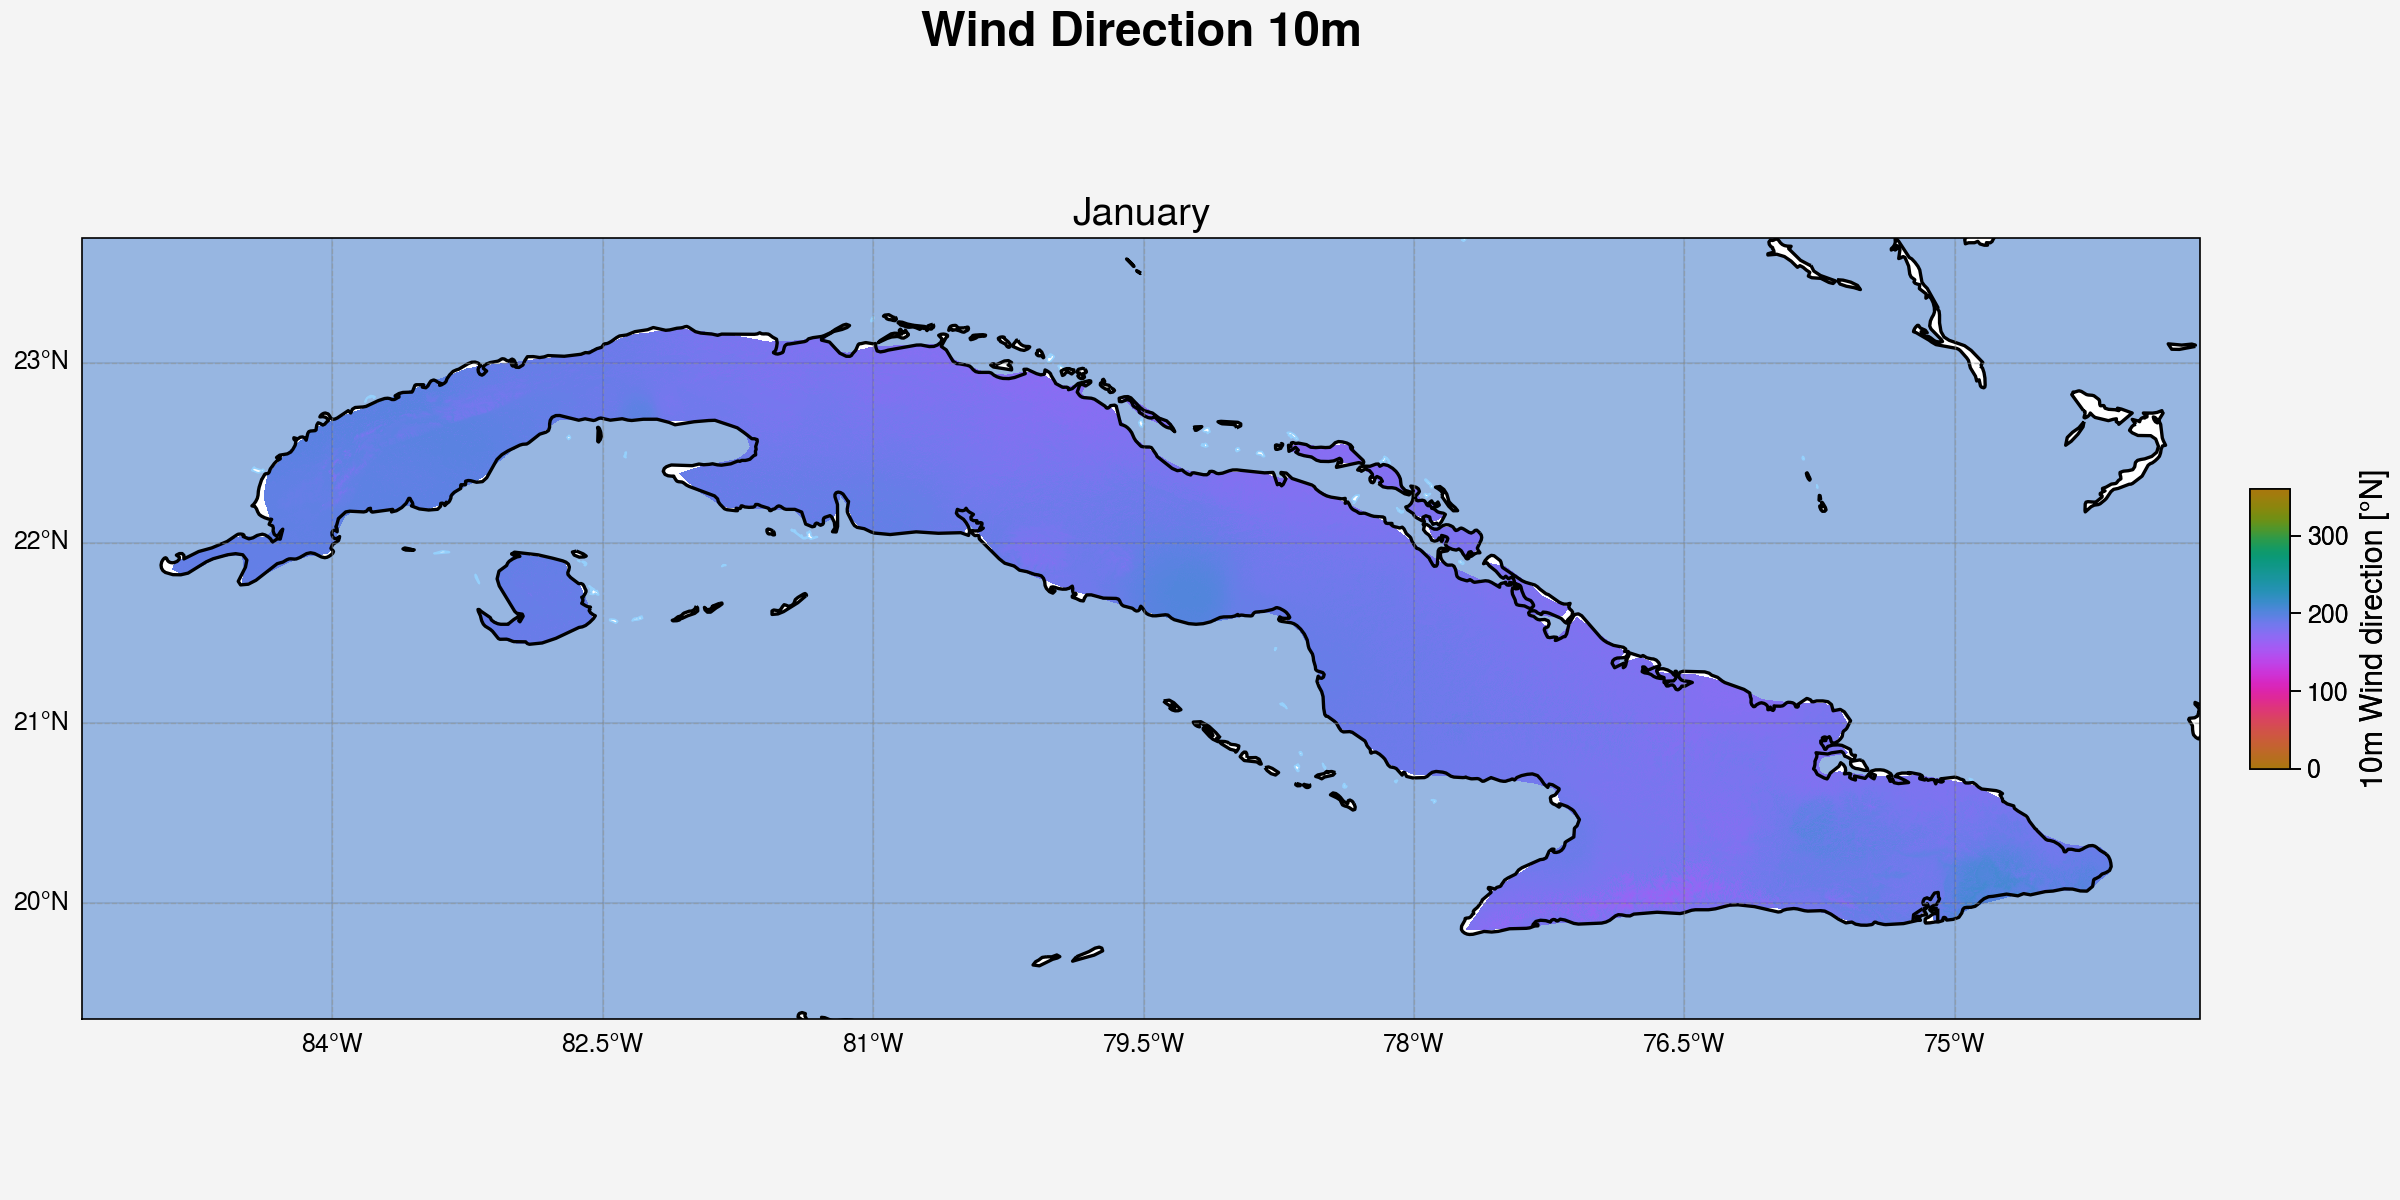

In [8]:
fig = draw_dir(xdf['dir_integrated'], 0, 360, True, '10m Wind direction [°N]', 
     months_names[month-1], 'Wind Direction 10m')
fig.savefig(f'{output_path}INTEGRATED_rd_{country}_overall_winddir_era5land_month{month}.png')

### Wind Speed

In [9]:
def draw_speed(xdf, vmin, vmax, legend=False, label=None, title=None, suptitle=None, orient='vertical'):
    
    fig, ax = plot.subplots(figsize=(12, 5), subplot_kw={'projection': ccrs.PlateCarree()})
    # Add features to the map

    ax.add_feature(cfeature.LAKES, edgecolor='black', facecolor='light blue')
    ax.add_feature(cfeature.OCEAN, edgecolor='light blue')
    ax.add_feature(cfeature.RIVERS, edgecolor='light blue')
    ax.add_feature(cfeature.COASTLINE, edgecolor='black', linewidth=1.2)
    ax.add_feature(cfeature.BORDERS, edgecolor='black', linewidth=1.2)

    xdf.rio.set_spatial_dims(x_dim="longitude", y_dim="latitude", inplace=True)
    xdf.rio.write_crs("epsg:4326", inplace=True)

    cbar_kwargs = {
        'orientation': 'vertical',
        'shrink': 0.25,
        'aspect': 50,
        'pad': 2,
        'label': label,
        'labelsize': 11,
        
    } if legend else None

    #xdf.plot(cmap='reds', ax=ax, vmin=vmin, vmax=vmax)
    im = xr.plot.pcolormesh(xdf, cmap='Speed',ax = ax, 
                        #norm=LogNorm(),
                        vmin=vmin, vmax=vmax,
                        add_colorbar=legend, 
                        add_labels=False, 
                        cbar_kwargs=cbar_kwargs, 
                       )

    if orient == 'horizontal':
        cbar = im.colorbar
        cbar.ax.tick_params(axis='y', rotation=90)
        
    # Add longitude-latitude grid
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
    gl.xlabels_top = False
    gl.ylabels_right = False
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER

    lat_min = np.min(xdf.latitude.values)
    lat_max = np.max(xdf.latitude.values)
    lon_min = np.min(xdf.longitude.values)
    lon_max = np.max(xdf.longitude.values)

    ax.set_extent([lon_min-0.5, lon_max+0.5, lat_min-0.5, lat_max+0.5], crs=ccrs.PlateCarree())
    ax.set_title(title, fontsize=14)
    fig.suptitle(suptitle,fontsize=17)

    return fig,ax

In [10]:
# Quiver plot of the wind vectors using the scaled components u and v
# To avoid drawing too many arrows, se set the "rate" parameter:
# a rate equal i.e. to 150 draws an arrow every 150 points on the lon,lat grid 
def overlay_quiver(xdf, ax, step, rate=150):
    xdf.rio.set_spatial_dims(x_dim="longitude", y_dim="latitude", inplace=True)
    xdf.rio.write_crs("epsg:4326", inplace=True)
    xdf = xdf.rio.clip(geometries)

    if step == True:
        ax.quiver(
            xdf.longitude[::rate], xdf.latitude[::rate],
            xdf["u10_integrated"][::rate, ::rate],
            xdf["v10_integrated"][::rate, ::rate],
            headlength=3, headwidth=3, headaxislength=5
        )
    else:
        ax.quiver(
            xdf.longitude, xdf.latitude,
            xdf["u10_integrated"], xdf["v10_integrated"],
            headlength=5, headwidth=3, headaxislength=5
        )

In [11]:
# Define a custom colormap that transitions through desired colors
#colors = ['#FFFFFF', '#D8BFD8', '#0000FF', '#00FF00', '#FFFF00', '#FF0000']#, '#000000']
# Create a custom colormap with 10 discrete steps
#cmap = plot.Colormap(colors, name='custom_colormap', N=20)

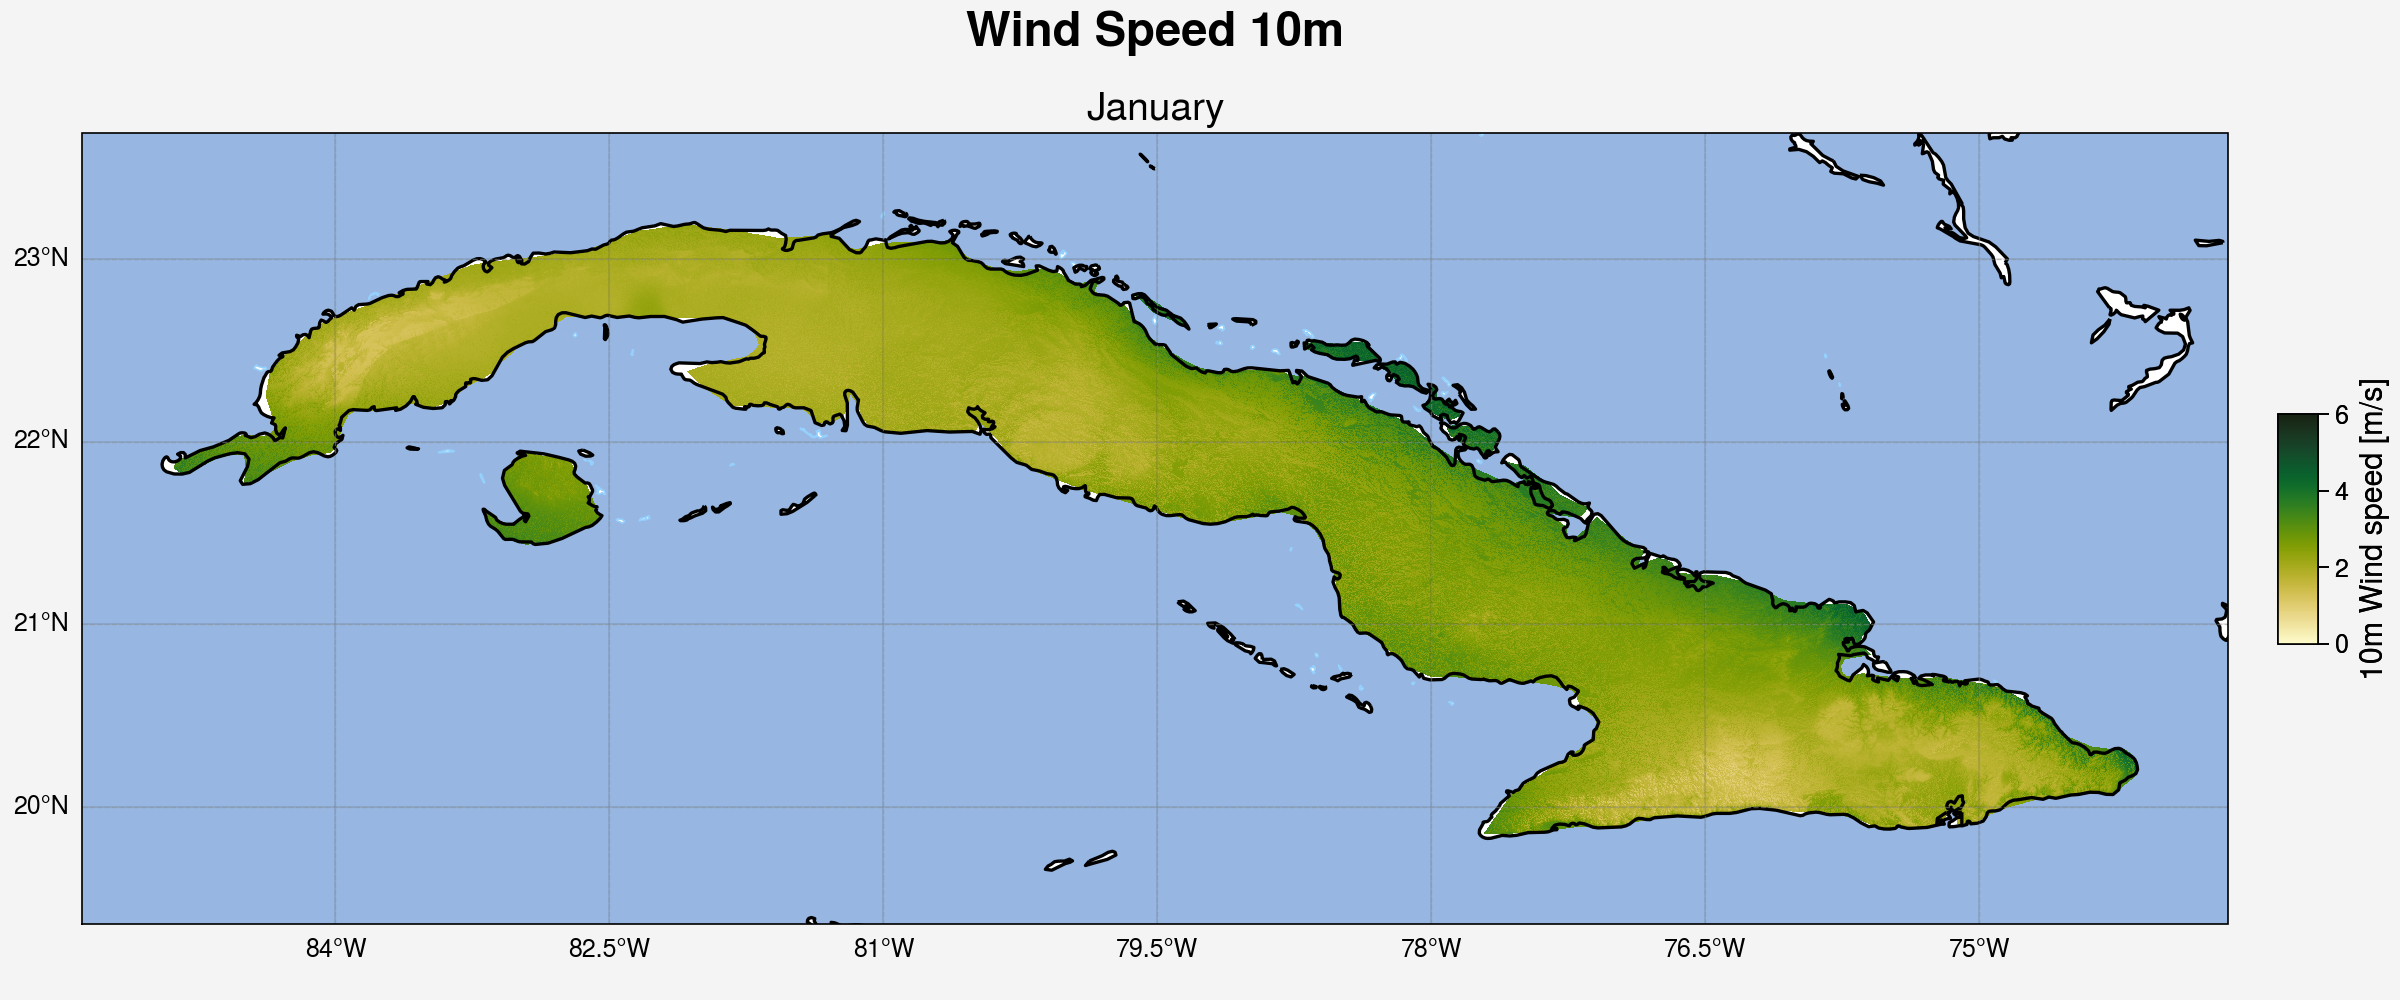

In [12]:
fig,ax = draw_speed(xdf['wds_integrated'], 0, 6, True, '10m Wind speed [m/s]', 
         months_names[month-1], 'Wind Speed 10m')
#overlay_quiver(xdf, ax, step = True)
fig.save(f'{output_path}INTEGRATED_rd_{country}_overall_windspeed_era5land_month{month}.png')